# 🍱 RescueBite
**A Deep Learning-Based Food Recognition, Spoilage Detection, and Surplus Food Rescue System**

1. Project Overview
RescueBite helps canteens and donors give away surplus food safely. A donor uploads a food photo and enters preparation and storage details. The system then:

1. **Recognizes the food** (MobileNetV2 transfer learning)
2. **Checks for visible spoilage** (second MobileNetV2 transfer-learning classifier, with an "uncertain" option)
3. **Applies food-safety time and storage rules** (a Python rules module, *not* a deep learning model) to decide whether the donation can go to NGO review and by when it must be collected
4. Shows eligible donations on an **NGO dashboard**

> ⚠️ **Important design rule:** a photograph cannot tell us how long food has been stored or at what temperature. The collection deadline is therefore calculated from the entered preparation/storage details, never predicted from the image. The system never approves a donation from an image result alone; a person always makes the final check.

**Working Flow of the Project**

Upload Food Image → Food Recognition → Spoilage Detection → Enter Preparation & Storage Details → Time & Storage Assessment → Donation Eligibility Review → NGO Dashboard

**How to use this notebook**
1. Runtime → Change runtime type → **T4 GPU**
2. Run the sections from top to bottom
3. In Section 2, provide your two datasets (folders of images, one folder per class)

**Section 1: Install Required Libraries and Set Up**
TensorFlow/Keras is used to build and train the models. scikit-learn and matplotlib are used for evaluation graphs. Streamlit and pyngrok are used for the web app.

In [1]:
!pip install -q streamlit pyngrok scikit-learn seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 52.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 57.8 MB/s eta 0:00:00


In [2]:
import os, json, zipfile, shutil, random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

# ---- Folders and settings ----
BASE_DIR  = "/content/rescuebite"
FOOD_DIR  = f"{BASE_DIR}/food_data"
SPOIL_DIR = f"{BASE_DIR}/spoilage_data"
MODEL_DIR = f"{BASE_DIR}/models"

IMG_SIZE   = (224, 224)
BATCH_SIZE = 32
SEED       = 42

for d in [BASE_DIR, FOOD_DIR, SPOIL_DIR, MODEL_DIR]:
    os.makedirs(d, exist_ok=True)

random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


**Section 2: Prepare the Datasets**

This notebook prepares two datasets automatically:

- **Food recognition:** downloaded from the configured Hugging Face dataset repository and arranged into one folder per food class.
- **Spoilage detection:** loaded from Hugging Face and arranged into `fresh/` and `spoiled/` folders.

The expected layout is:

```text
food_data/
   class_1/
   class_2/
   ...

spoilage_data/
   fresh/
   spoiled/
```

A "fresh" image label does not prove that food is safe to eat. The model only learns patterns in the dataset labels. The final food-safety decision requires human inspection and verified storage history.

In [3]:
# ---- Helper functions for datasets ----
from google.colab import files

IMAGE_EXT = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

def find_dataset_root(path):
    """If the zip had one extra top folder, step into it until we reach the class folders."""
    while True:
        entries = [e for e in os.listdir(path) if not e.startswith(".") and e != "__MACOSX"]
        subdirs = [e for e in entries if os.path.isdir(os.path.join(path, e))]
        loose   = [e for e in entries if os.path.isfile(os.path.join(path, e))]
        if len(subdirs) == 1 and not loose:
            path = os.path.join(path, subdirs[0])
        else:
            return path

def upload_zip(target_dir):
    print(f"Upload the ZIP file for: {target_dir}")
    uploaded = files.upload()
    for name in uploaded:
        if name.lower().endswith(".zip"):
            with zipfile.ZipFile(name) as z:
                z.extractall(target_dir)
            os.remove(name)
    return find_dataset_root(target_dir)

def kaggle_download(slug, target_dir):
    """Needs kaggle.json (Kaggle > Settings > Create New Token)."""
    os.makedirs("/root/.kaggle", exist_ok=True)
    if not os.path.exists("/root/.kaggle/kaggle.json"):
        print("Upload your kaggle.json file")
        up = files.upload()
        shutil.move("kaggle.json", "/root/.kaggle/kaggle.json")
        os.chmod("/root/.kaggle/kaggle.json", 0o600)
    !kaggle datasets download -d {slug} -p {target_dir} --unzip
    return find_dataset_root(target_dir)

**Section 2: Prepare the Datasets (online sources)**
This notebook downloads the food images from Hugging Face and loads the fresh/rotten dataset directly. No manual ZIP upload is needed.

In [4]:
!pip install -q huggingface_hub

# Download the food dataset and arrange it for image_dataset_from_directory.
from huggingface_hub import snapshot_download
from pathlib import Path
import os, shutil

FOOD_SOURCE = snapshot_download(
    repo_id="SKSKCulinaryAI/Indian_Food_Images_Dataset",
    repo_type="dataset"
)

FOOD_ROOT = "/content/rescuebite/food_data"
IMAGE_EXT = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

# Rebuild the prepared folder to avoid stale/empty folders from earlier attempts.
if os.path.exists(FOOD_ROOT):
    shutil.rmtree(FOOD_ROOT)
os.makedirs(FOOD_ROOT, exist_ok=True)

source_path = Path(FOOD_SOURCE)
image_count = 0
class_counts = {}

# This repository is organized into split folders (for example train/ and valid/).
# Combine the split images into one folder per food class; the notebook will split them later.
split_names = {"train", "valid", "validation", "test", "training"}
for split_dir in [p for p in source_path.iterdir() if p.is_dir() and p.name.lower() in split_names]:
    for class_dir in [p for p in split_dir.iterdir() if p.is_dir()]:
        class_name = class_dir.name.strip()
        out_dir = Path(FOOD_ROOT) / class_name
        out_dir.mkdir(parents=True, exist_ok=True)
        for img_path in class_dir.rglob("*"):
            if img_path.is_file() and img_path.suffix.lower() in IMAGE_EXT:
                # Prefix with split and a running number to avoid filename collisions.
                dest = out_dir / f"{split_dir.name}_{image_count:07d}{img_path.suffix.lower()}"
                shutil.copy2(img_path, dest)
                class_counts[class_name] = class_counts.get(class_name, 0) + 1
                image_count += 1

# Fallback for repositories that put class folders directly at the root.
if image_count == 0:
    for class_dir in [p for p in source_path.iterdir() if p.is_dir() and p.name.lower() not in split_names]:
        for img_path in class_dir.rglob("*"):
            if img_path.is_file() and img_path.suffix.lower() in IMAGE_EXT:
                out_dir = Path(FOOD_ROOT) / class_dir.name
                out_dir.mkdir(parents=True, exist_ok=True)
                dest = out_dir / f"{image_count:07d}{img_path.suffix.lower()}"
                shutil.copy2(img_path, dest)
                class_counts[class_dir.name] = class_counts.get(class_dir.name, 0) + 1
                image_count += 1

print("Food dataset source:", FOOD_SOURCE)
print("Prepared FOOD_ROOT:", FOOD_ROOT)
print("Total food images copied:", image_count)
print("Food classes and image counts:", class_counts)

if image_count == 0 or len(class_counts) < 2:
    raise RuntimeError(
        "Could not find at least two food classes with images. "
        "Inspect the repository folders shown above and adjust the class-folder paths."
    )


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 10774 files:   0%|          | 0/10774 [00:00<?, ?it/s]

Food dataset source: /root/.cache/huggingface/hub/datasets--SKSKCulinaryAI--Indian_Food_Images_Dataset/snapshots/fd2bc1f0b513339211d717d8150b977dbf4df8c8
Prepared FOOD_ROOT: /content/rescuebite/food_data
Total food images copied: 10773
Food classes and image counts: {'Rasgulla': 453, 'Dhokla': 424, 'Kadai_paneer': 429, 'Jalebi': 420, 'Dosa': 423, 'Kathi roll': 419, 'Biryani': 469, 'Pav bhaji': 435, 'Ghevar': 436, 'Vada pav': 405, 'Idli': 411, 'Gulab jamun': 425, 'Samosa': 415, 'Meduvada': 423, 'Poori': 437, 'Kofta': 429, 'Toor dal': 448, 'Butter chicken': 430, 'Pani puri': 427, 'Chole bhature': 446, 'Chicken tandoori': 421, 'Dal makhani': 429, 'Gajar halwa': 442, 'Masala bhindi': 427, 'Chappati': 450}


**Online spoilage dataset:** The next cells load the public Hugging Face fresh/rotten fruit dataset and save images directly into `SPOIL_ROOT/fresh` and `SPOIL_ROOT/spoiled`. This matches the existing counting and TensorFlow directory-loader functions.

In [5]:
!pip install -q datasets

In [6]:
from datasets import load_dataset
from collections import Counter

dataset = load_dataset("Project-AgML/fresh_rotten_fruit_classification")
print(dataset)
print("Features:", dataset["train"].features)
print("Label counts:", Counter(dataset["train"]["label"]))
print("Fruit types:", Counter(dataset["train"]["fruit_type"]))


README.md:   0%|          | 0.00/2.05k [00:00<?, ?B/s]

raw/train-00000-of-00004.parquet: reconstructing file:   0%|          |  0.00B /  324MB            

raw/train-00000-of-00004.parquet: downloading bytes:           |  0.00B            

raw/train-00001-of-00004.parquet: reconstructing file:   0%|          |  0.00B /  964MB            

raw/train-00001-of-00004.parquet: downloading bytes:           |  0.00B            

raw/train-00002-of-00004.parquet: reconstructing file:   0%|          |  0.00B /  656MB            

raw/train-00002-of-00004.parquet: downloading bytes:           |  0.00B            

raw/train-00003-of-00004.parquet: reconstructing file:   0%|          |  0.00B /  913MB            

raw/train-00003-of-00004.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/3200 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'label', 'fruit_type'],
        num_rows: 3200
    })
})
Features: {'image': Image(mode=None, decode=True), 'label': ClassLabel(names=['fresh', 'rotten']), 'fruit_type': Value('string')}
Label counts: Counter({0: 1600, 1: 1600})
Fruit types: Counter({'apple': 400, 'banana': 400, 'grape': 400, 'guava': 400, 'jujube': 400, 'orange': 400, 'pomegranate': 400, 'strawberry': 400})


In [7]:
# Prepare spoilage images in the flat class-folder structure expected by the notebook.
from pathlib import Path
from tqdm.auto import tqdm
import shutil

SPOIL_ROOT = "/content/rescuebite/spoilage_data"

if os.path.exists(SPOIL_ROOT):
    shutil.rmtree(SPOIL_ROOT)
os.makedirs(SPOIL_ROOT, exist_ok=True)

label_names = {0: "fresh", 1: "spoiled"}
saved_counts = Counter()

for i, item in enumerate(tqdm(dataset["train"], desc="Saving spoilage images")):
    class_name = label_names[int(item["label"])]
    fruit = str(item["fruit_type"]).strip().lower().replace(" ", "_")
    class_dir = Path(SPOIL_ROOT) / class_name
    class_dir.mkdir(parents=True, exist_ok=True)

    # Keep fruit type in the filename while storing images directly under the class folder.
    image_path = class_dir / f"{fruit}_{i:05d}.jpg"
    item["image"].convert("RGB").save(image_path, format="JPEG", quality=88)
    saved_counts[class_name] += 1

print("\\nSpoilage dataset preparation completed.")
print("Spoilage dataset folder:", SPOIL_ROOT)
print("Saved counts:", dict(saved_counts))
assert saved_counts.get("fresh", 0) > 0 and saved_counts.get("spoiled", 0) > 0, \
    "Expected both fresh and spoiled image classes."


Saving spoilage images:   0%|          | 0/3200 [00:00<?, ?it/s]

\nSpoilage dataset preparation completed.
Spoilage dataset folder: /content/rescuebite/spoilage_data
Saved counts: {'fresh': 1600, 'spoiled': 1600}


In [8]:
print("Verified label mapping:", dataset["train"].features["label"])
print("Expected labels: 0 = fresh, 1 = rotten (saved into fresh/ and spoiled/ folders)")
print("Food dataset root:", FOOD_ROOT)
print("Spoilage dataset root:", SPOIL_ROOT)


Verified label mapping: ClassLabel(names=['fresh', 'rotten'])
Expected labels: 0 = fresh, 1 = rotten (saved into fresh/ and spoiled/ folders)
Food dataset root: /content/rescuebite/food_data
Spoilage dataset root: /content/rescuebite/spoilage_data


Both datasets are now prepared as folders containing one subfolder per class. Continue to the dataset-counting section below.

**Section 3: Check the Datasets**
Count the images in each class and plot them. Very small or very uneven classes will give unreliable models.

Food recognition dataset
  Biryani: 469
  Butter chicken: 430
  Chappati: 450
  Chicken tandoori: 421
  Chole bhature: 446
  Dal makhani: 429
  Dhokla: 424
  Dosa: 423
  Gajar halwa: 442
  Ghevar: 436
  Gulab jamun: 425
  Idli: 411
  Jalebi: 420
  Kadai_paneer: 429
  Kathi roll: 419
  Kofta: 429
  Masala bhindi: 427
  Meduvada: 423
  Pani puri: 427
  Pav bhaji: 435
  Poori: 437
  Rasgulla: 453
  Samosa: 415
  Toor dal: 448
  Vada pav: 405


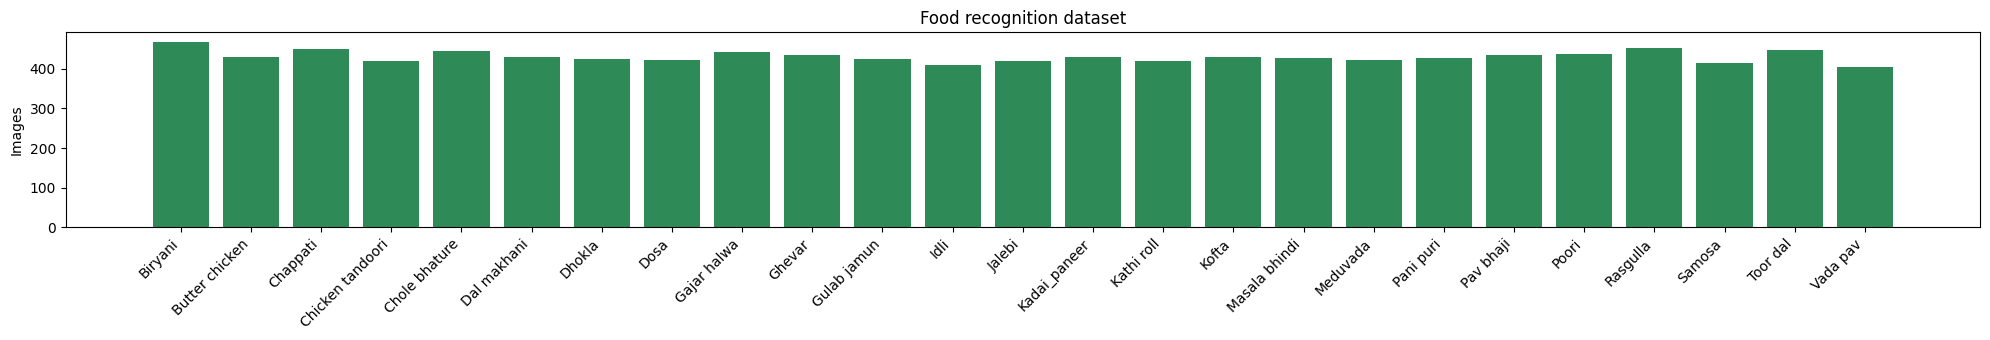

Spoilage dataset
  fresh: 1600
  spoiled: 1600


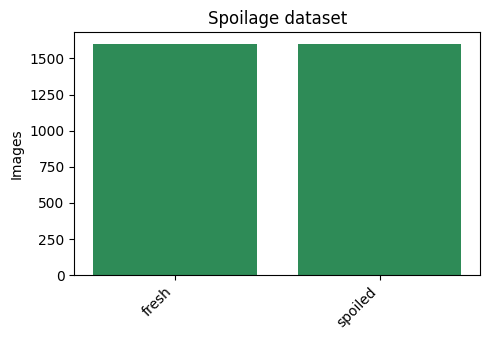

In [9]:
def count_images(root):
    counts = {}
    for cls in sorted(os.listdir(root)):
        p = os.path.join(root, cls)
        if os.path.isdir(p):
            counts[cls] = len([f for f in os.listdir(p) if f.lower().endswith(IMAGE_EXT)])
    return counts

def show_counts(root, title):
    counts = count_images(root)
    print(title)
    for k, v in counts.items():
        print(f"  {k}: {v}")
        if v < 50:
            print("    ⚠️ fewer than 50 images, consider adding more")
    assert len(counts) >= 2, "Need at least 2 class folders"
    plt.figure(figsize=(max(5, len(counts) * 0.8), 3.5))
    plt.bar(counts.keys(), counts.values(), color="#2e8b57")
    plt.title(title); plt.xticks(rotation=45, ha="right"); plt.ylabel("Images")
    plt.tight_layout(); plt.show()

show_counts(FOOD_ROOT,  "Food recognition dataset")
show_counts(SPOIL_ROOT, "Spoilage dataset")

**Section 4: Load Data (Train / Validation / Test)**
Each dataset is split into **70% training, 15% validation and 15% test**. The test images are never used during training, so they give an honest measure of performance on unseen data.

In [10]:
AUTOTUNE = tf.data.AUTOTUNE

def make_datasets(root):
    train = keras.utils.image_dataset_from_directory(
        root, validation_split=0.30, subset="training", seed=SEED,
        image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode="categorical")
    held = keras.utils.image_dataset_from_directory(
        root, validation_split=0.30, subset="validation", seed=SEED,
        image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode="categorical")
    class_names = train.class_names

    n = tf.data.experimental.cardinality(held).numpy()
    assert n >= 2, "Not enough images to make validation and test sets. Add more images."
    val  = held.take(n // 2)
    test = held.skip(n // 2)
    return (train.prefetch(AUTOTUNE), val.prefetch(AUTOTUNE),
            test.prefetch(AUTOTUNE), class_names)

food_train, food_val, food_test, food_classes = make_datasets(FOOD_ROOT)
print("\nFood classes:", food_classes)

Found 10773 files belonging to 25 classes.
Using 7542 files for training.
Found 10773 files belonging to 25 classes.
Using 3231 files for validation.

Food classes: ['Biryani', 'Butter chicken', 'Chappati', 'Chicken tandoori', 'Chole bhature', 'Dal makhani', 'Dhokla', 'Dosa', 'Gajar halwa', 'Ghevar', 'Gulab jamun', 'Idli', 'Jalebi', 'Kadai_paneer', 'Kathi roll', 'Kofta', 'Masala bhindi', 'Meduvada', 'Pani puri', 'Pav bhaji', 'Poori', 'Rasgulla', 'Samosa', 'Toor dal', 'Vada pav']


In [11]:
spoil_train, spoil_val, spoil_test, spoil_classes = make_datasets(SPOIL_ROOT)
print("\nSpoilage classes:", spoil_classes)

Found 3200 files belonging to 2 classes.
Using 2240 files for training.
Found 3200 files belonging to 2 classes.
Using 960 files for validation.

Spoilage classes: ['fresh', 'spoiled']


**Section 5: Build the Models (Transfer Learning)**
Both image models use **MobileNetV2** pretrained on ImageNet. Think of it as hiring someone who already knows how to "see" shapes and textures, then teaching them only your specific foods. Training happens in two steps: first only the new top layers learn, then the last few MobileNetV2 layers are gently fine-tuned.

In [12]:
def build_model(num_classes):
    augment = keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.1),
        layers.RandomContrast(0.1),
    ], name="augmentation")

    base = keras.applications.MobileNetV2(
        input_shape=IMG_SIZE + (3,), include_top=False, weights="imagenet")
    base.trainable = False

    inputs = keras.Input(shape=IMG_SIZE + (3,))
    x = augment(inputs)
    x = keras.applications.mobilenet_v2.preprocess_input(x)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)
    return keras.Model(inputs, outputs), base

def train_model(model, base, train_ds, val_ds, head_epochs=8, ft_epochs=5):
    early = keras.callbacks.EarlyStopping(
        monitor="val_accuracy", patience=3, restore_best_weights=True)

    # Step 1: train only the new top layers
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss="categorical_crossentropy", metrics=["accuracy"])
    h1 = model.fit(train_ds, validation_data=val_ds, epochs=head_epochs, callbacks=[early])

    # Step 2: fine-tune the last 30 layers of MobileNetV2 with a small learning rate
    base.trainable = True
    for layer in base.layers[:-30]:
        layer.trainable = False
    model.compile(optimizer=keras.optimizers.Adam(1e-5),
                  loss="categorical_crossentropy", metrics=["accuracy"])
    h2 = model.fit(train_ds, validation_data=val_ds, epochs=ft_epochs, callbacks=[early])

    merged = {k: h1.history[k] + h2.history[k] for k in h1.history}
    return merged, len(h1.history["loss"])

**Section 6: Train the Food Recognition Model**

In [14]:
food_model, food_base = build_model(len(food_classes))
food_history, food_split = train_model(food_model, food_base, food_train, food_val)

Epoch 1/8
236/236 ━━━━━━━━━━━━━━━━━━━━ 23s 79ms/step - accuracy: 0.5290 - loss: 1.6248 - val_accuracy: 0.7606 - val_loss: 0.8786
Epoch 2/8
236/236 ━━━━━━━━━━━━━━━━━━━━ 18s 75ms/step - accuracy: 0.7505 - loss: 0.8366 - val_accuracy: 0.7950 - val_loss: 0.6903
Epoch 3/8
236/236 ━━━━━━━━━━━━━━━━━━━━ 17s 73ms/step - accuracy: 0.7970 - loss: 0.6739 - val_accuracy: 0.8213 - val_loss: 0.6159
Epoch 4/8
236/236 ━━━━━━━━━━━━━━━━━━━━ 17s 73ms/step - accuracy: 0.8164 - loss: 0.5923 - val_accuracy: 0.8288 - val_loss: 0.5567
Epoch 5/8
236/236 ━━━━━━━━━━━━━━━━━━━━ 17s 72ms/step - accuracy: 0.8319 - loss: 0.5447 - val_accuracy: 0.8469 - val_loss: 0.5132
Epoch 6/8
236/236 ━━━━━━━━━━━━━━━━━━━━ 17s 73ms/step - accuracy: 0.8479 - loss: 0.4899 - val_accuracy: 0.8550 - val_loss: 0.4859
Epoch 7/8
236/236 ━━━━━━━━━━━━━━━━━━━━ 17s 73ms/step - accuracy: 0.8540 - loss: 0.4750 - val_accuracy: 0.8544 - val_loss: 0.4796
Epoch 8/8
236/236 ━━━━━━━━━━━━━━━━━━━━ 20s 72ms/step - accuracy: 0.8559 - loss: 0.4625 - val_accu

**Section 7: Train the Spoilage Detection Model**
This model learns visual patterns that match your "fresh" and "spoiled" examples. It cannot know whether food is actually safe to eat, which is why Section 10 adds an "uncertain" result.

In [17]:
spoil_model, spoil_base = build_model(len(spoil_classes))
spoil_history, spoil_split = train_model(spoil_model, spoil_base, spoil_train, spoil_val)

Epoch 1/8
70/70 ━━━━━━━━━━━━━━━━━━━━ 56s 731ms/step - accuracy: 0.7991 - loss: 0.4184 - val_accuracy: 0.8833 - val_loss: 0.2651
Epoch 2/8
70/70 ━━━━━━━━━━━━━━━━━━━━ 52s 746ms/step - accuracy: 0.8978 - loss: 0.2580 - val_accuracy: 0.9042 - val_loss: 0.2233
Epoch 3/8
70/70 ━━━━━━━━━━━━━━━━━━━━ 50s 710ms/step - accuracy: 0.9138 - loss: 0.2132 - val_accuracy: 0.9312 - val_loss: 0.1861
Epoch 4/8
70/70 ━━━━━━━━━━━━━━━━━━━━ 84s 741ms/step - accuracy: 0.9228 - loss: 0.1840 - val_accuracy: 0.9354 - val_loss: 0.1589
Epoch 5/8
70/70 ━━━━━━━━━━━━━━━━━━━━ 52s 748ms/step - accuracy: 0.9353 - loss: 0.1700 - val_accuracy: 0.9458 - val_loss: 0.1476
Epoch 6/8
70/70 ━━━━━━━━━━━━━━━━━━━━ 50s 714ms/step - accuracy: 0.9402 - loss: 0.1588 - val_accuracy: 0.9312 - val_loss: 0.1511
Epoch 7/8
70/70 ━━━━━━━━━━━━━━━━━━━━ 49s 696ms/step - accuracy: 0.9451 - loss: 0.1438 - val_accuracy: 0.9542 - val_loss: 0.1197
Epoch 8/8
70/70 ━━━━━━━━━━━━━━━━━━━━ 50s 713ms/step - accuracy: 0.9473 - loss: 0.1388 - val_accuracy: 0.

**Section 8: Evaluate the Models**
Training/validation graphs, a classification report and a confusion matrix on the **unseen test set**. These are the results to show your faculty.

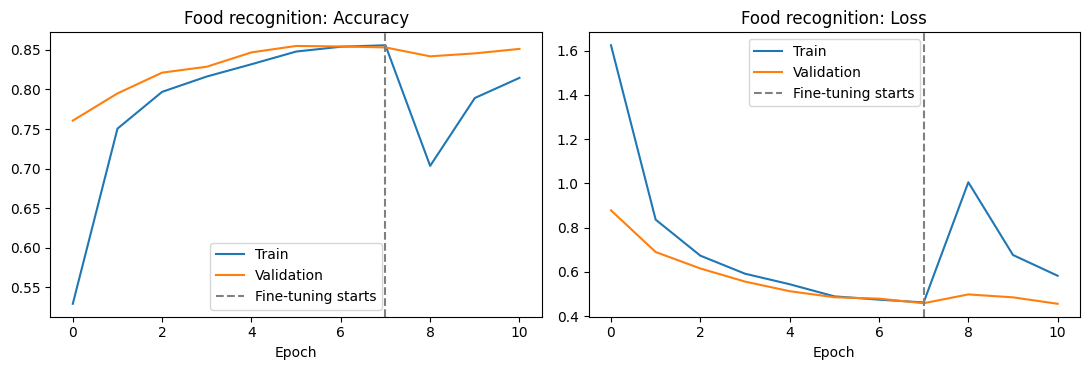

Food recognition test accuracy: 84.18%  (1631 test images)

                  precision    recall  f1-score   support

         Biryani       0.72      0.92      0.81        63
  Butter chicken       0.83      0.52      0.64        65
        Chappati       0.95      0.90      0.92        77
Chicken tandoori       0.96      0.85      0.90        61
   Chole bhature       0.93      0.71      0.81        73
     Dal makhani       0.88      0.85      0.86        52
          Dhokla       0.97      0.87      0.92        70
            Dosa       0.80      0.97      0.87        61
     Gajar halwa       0.84      0.74      0.79        70
          Ghevar       0.89      0.84      0.86        64
     Gulab jamun       0.89      1.00      0.94        64
            Idli       0.95      0.80      0.87        66
          Jalebi       0.97      0.96      0.96        68
    Kadai_paneer       0.51      0.93      0.66        67
      Kathi roll       0.88      0.93      0.91        57
           

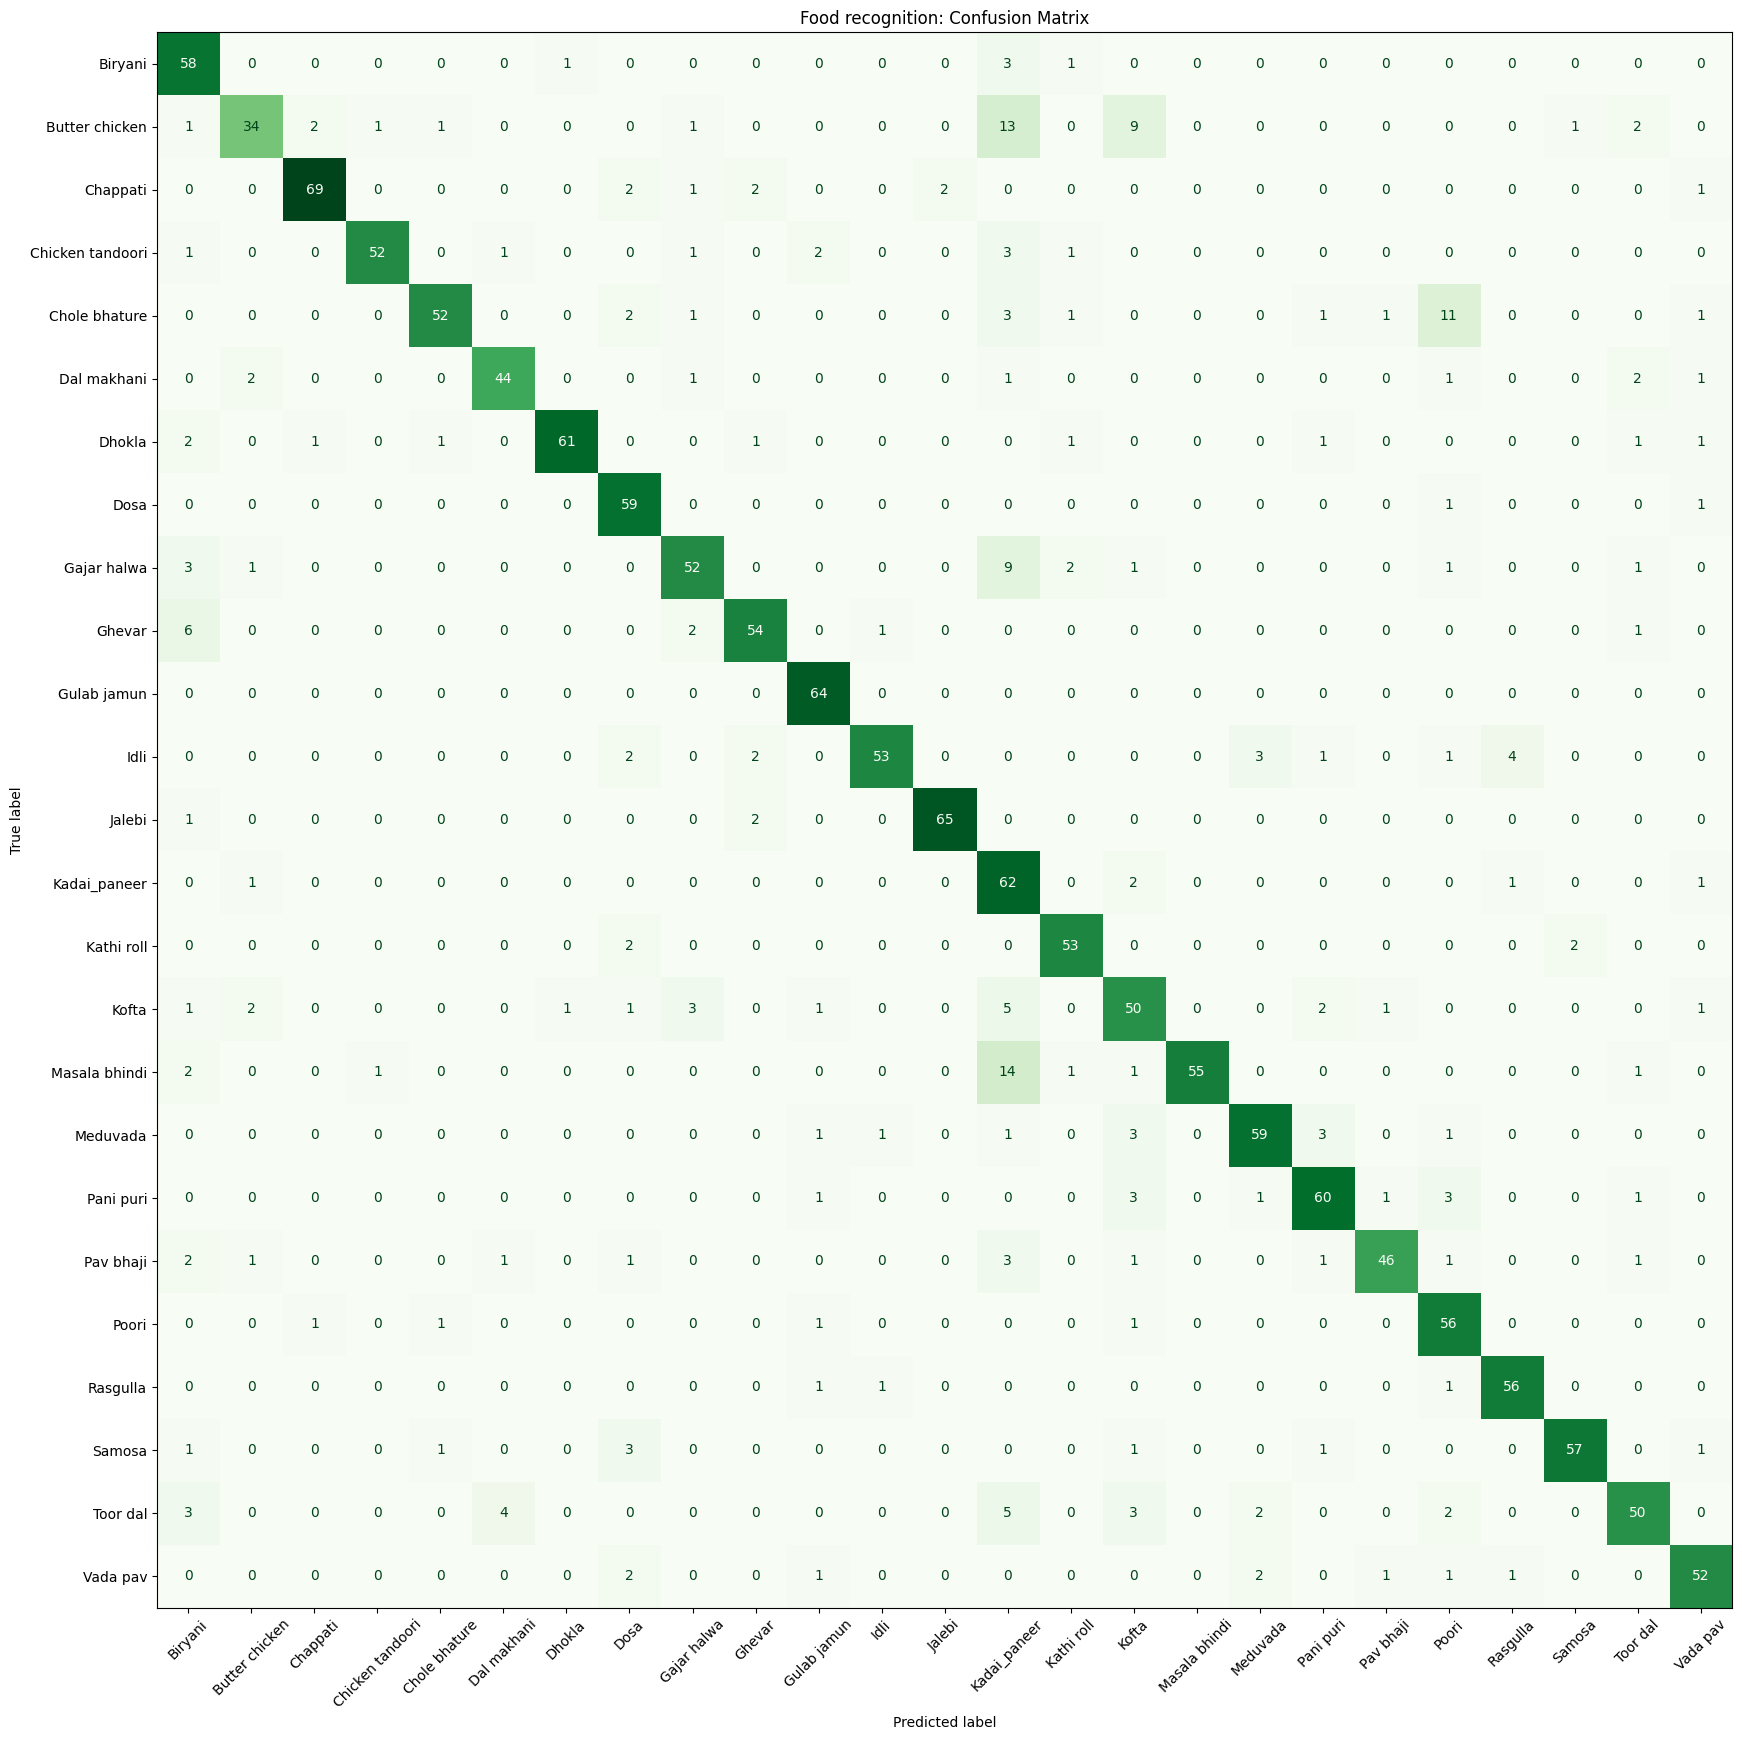

In [18]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

def plot_history(hist, split, title):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    for a, key, name in zip(ax, ["accuracy", "loss"], ["Accuracy", "Loss"]):
        a.plot(hist[key], label="Train")
        a.plot(hist["val_" + key], label="Validation")
        a.axvline(split - 1, color="gray", linestyle="--", label="Fine-tuning starts")
        a.set_title(f"{title}: {name}"); a.set_xlabel("Epoch"); a.legend()
    plt.tight_layout(); plt.show()

def evaluate_model(model, test_ds, class_names, title):
    y_true, y_pred = [], []
    for x, y in test_ds:
        p = model.predict(x, verbose=0)
        y_true += list(np.argmax(y.numpy(), axis=1))
        y_pred += list(np.argmax(p, axis=1))
    y_true, y_pred = np.array(y_true), np.array(y_pred)

    print(f"{title} test accuracy: {np.mean(y_true == y_pred):.2%}  ({len(y_true)} test images)\n")
    labels = list(range(len(class_names)))
    print(classification_report(y_true, y_pred, labels=labels,
                                target_names=class_names, zero_division=0))
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    fig, ax = plt.subplots(figsize=(max(5, len(class_names) * 0.7),) * 2)
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
        ax=ax, cmap="Greens", xticks_rotation=45, colorbar=False)
    ax.set_title(f"{title}: Confusion Matrix"); plt.tight_layout(); plt.show()

plot_history(food_history, food_split, "Food recognition")
evaluate_model(food_model, food_test, food_classes, "Food recognition")

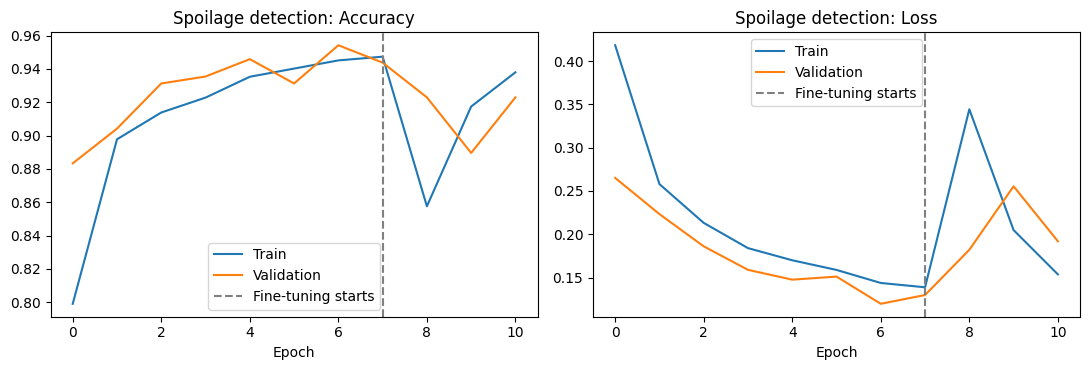

Spoilage detection test accuracy: 93.75%  (480 test images)

              precision    recall  f1-score   support

       fresh       0.89      1.00      0.94       237
     spoiled       1.00      0.88      0.93       243

    accuracy                           0.94       480
   macro avg       0.94      0.94      0.94       480
weighted avg       0.94      0.94      0.94       480



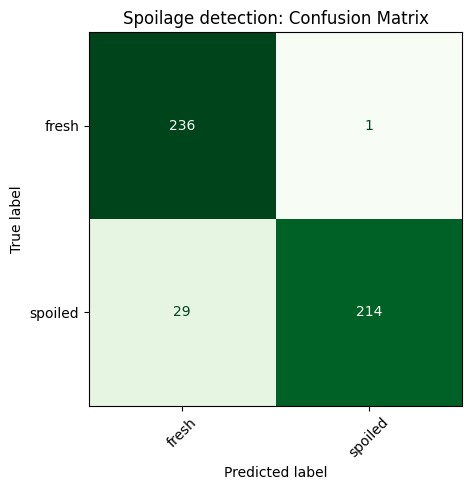

In [19]:
plot_history(spoil_history, spoil_split, "Spoilage detection")
evaluate_model(spoil_model, spoil_test, spoil_classes, "Spoilage detection")

**Section 9: Sample Predictions**
A quick visual check: true label vs predicted label with confidence.

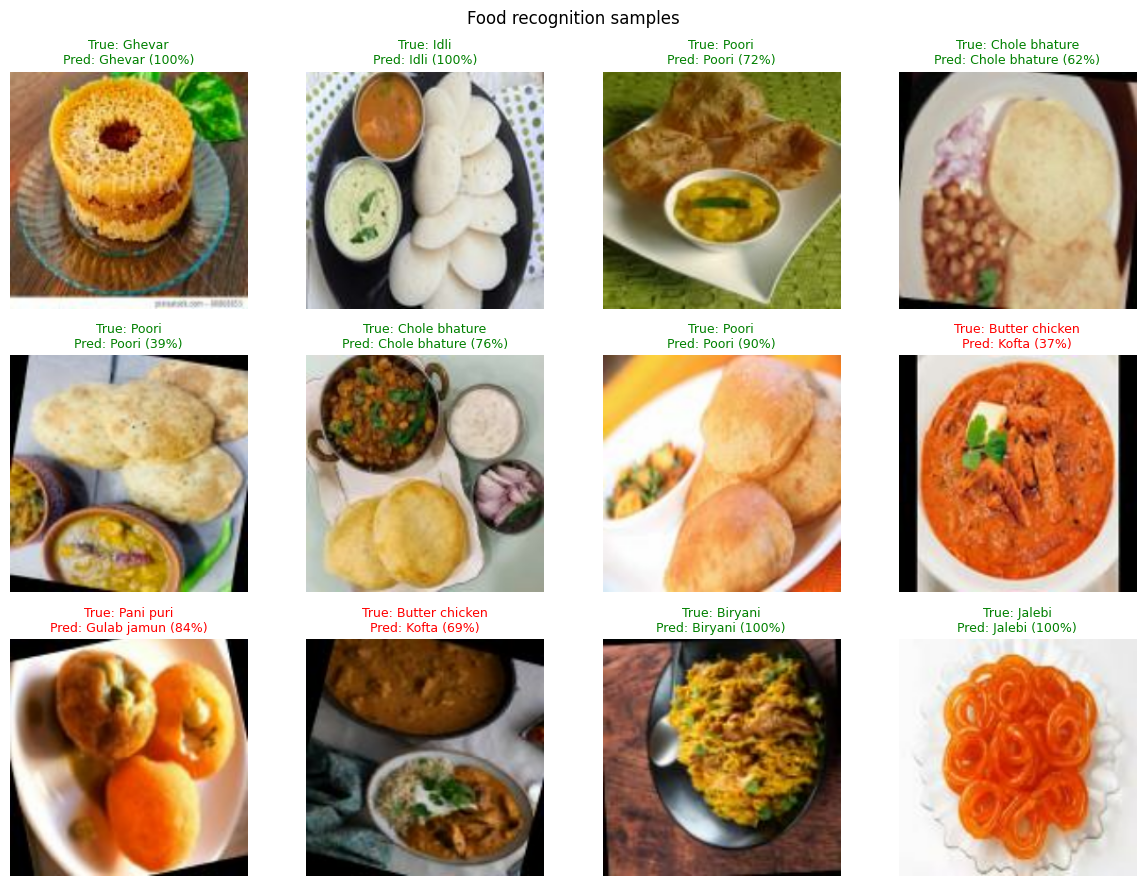

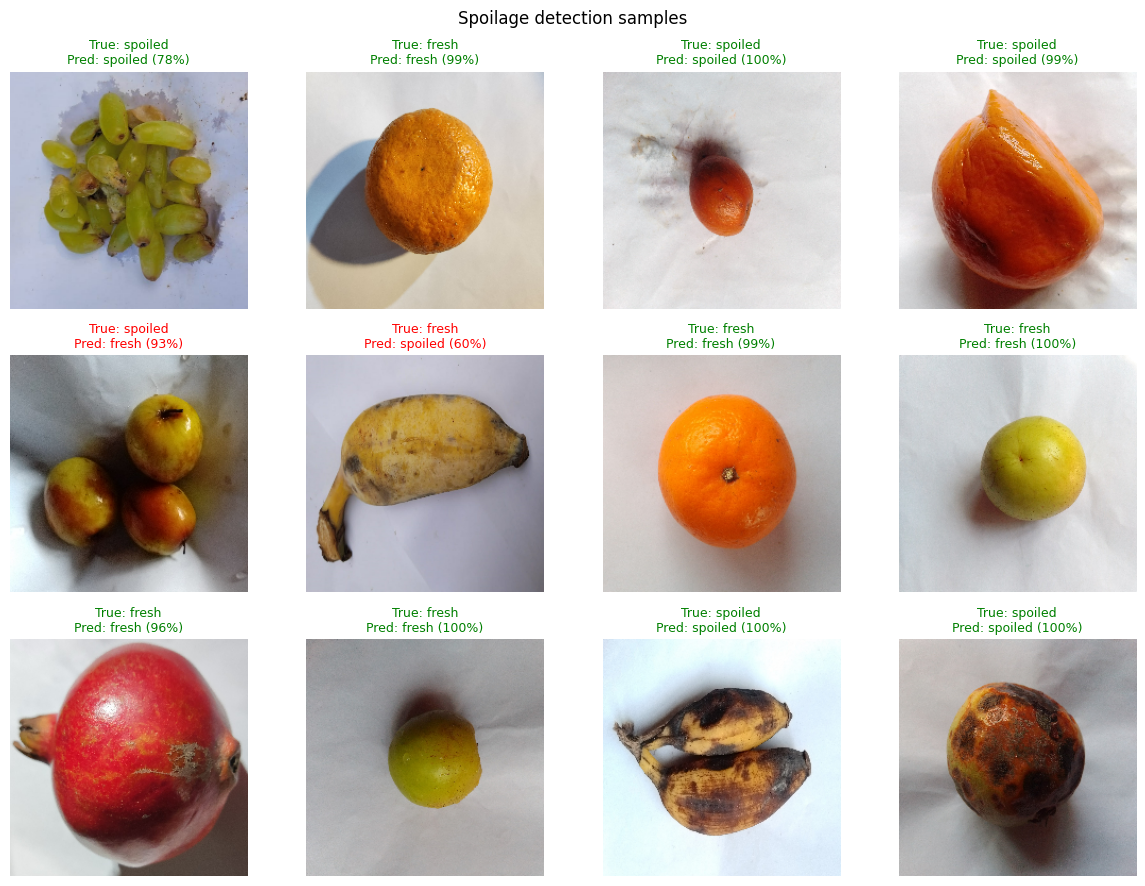

In [20]:
def show_samples(model, ds, class_names, title, n=12):
    images, labels = next(iter(ds.unbatch().batch(n)))
    probs = model.predict(images, verbose=0)
    plt.figure(figsize=(12, 9))
    for i in range(len(images)):
        plt.subplot(3, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8")); plt.axis("off")
        true = class_names[np.argmax(labels[i])]
        pred = class_names[np.argmax(probs[i])]
        color = "green" if true == pred else "red"
        plt.title(f"True: {true}\nPred: {pred} ({probs[i].max():.0%})", color=color, fontsize=9)
    plt.suptitle(title); plt.tight_layout(); plt.show()

show_samples(food_model,  food_test,  food_classes,  "Food recognition samples")
show_samples(spoil_model, spoil_test, spoil_classes, "Spoilage detection samples")

**Section 10: Spoilage Result with an "Uncertain" Option**
The spoilage model gives one of three outcomes:

* **Fresh-looking**
* **Visible signs of spoilage**
* **Uncertain, needs further inspection** (when the model's confidence is below a threshold)

Set `SPOILED_KEYWORDS` so that your spoiled folder name(s) are recognised, then check the printed mapping.

In [21]:
UNCERTAIN_THRESHOLD = 0.75      # below this confidence the spoilage result becomes "uncertain"
FOOD_THRESHOLD      = 0.60      # below this confidence the food name is flagged as low-confidence
SPOILED_KEYWORDS    = ["spoil", "rotten", "stale", "mold", "mould"]

def is_spoiled_class(name):
    return any(k in name.lower() for k in SPOILED_KEYWORDS)

print("Spoilage class mapping:")
for c in spoil_classes:
    print(f"  {c} -> {'visible spoilage' if is_spoiled_class(c) else 'fresh-looking'}")

def visual_condition(probs, class_names):
    idx = int(np.argmax(probs)); conf = float(probs[idx])
    if conf < UNCERTAIN_THRESHOLD:
        return "uncertain", conf
    return ("visible spoilage" if is_spoiled_class(class_names[idx]) else "fresh-looking"), conf

# How often does the model abstain, and how accurate is it when it does answer?
y_true, y_prob = [], []
for x, y in spoil_test:
    y_prob.append(spoil_model.predict(x, verbose=0))
    y_true += list(np.argmax(y.numpy(), axis=1))
y_prob = np.concatenate(y_prob); y_true = np.array(y_true)
y_pred = y_prob.argmax(axis=1); conf = y_prob.max(axis=1)
confident = conf >= UNCERTAIN_THRESHOLD
print(f"\nMarked 'uncertain': {np.mean(~confident):.1%} of test images")
if confident.any():
    print(f"Accuracy on the confident predictions: {np.mean(y_pred[confident] == y_true[confident]):.2%}")

Spoilage class mapping:
  fresh -> fresh-looking
  spoiled -> visible spoilage

Marked 'uncertain': 8.3% of test images
Accuracy on the confident predictions: 95.23%


**Section 11: Save the Models**
The models and settings are saved so the web app can load them. They are also zipped so you can download a copy before the Colab session ends.

In [22]:
food_model.save(f"{MODEL_DIR}/food_model.keras")
spoil_model.save(f"{MODEL_DIR}/spoilage_model.keras")

meta = {
    "food_classes": food_classes,
    "spoilage_classes": spoil_classes,
    "spoiled_keywords": SPOILED_KEYWORDS,
    "uncertain_threshold": UNCERTAIN_THRESHOLD,
    "food_threshold": FOOD_THRESHOLD,
    "img_size": list(IMG_SIZE),
}
with open(f"{MODEL_DIR}/meta.json", "w") as f:
    json.dump(meta, f, indent=2)

print("Saved:", os.listdir(MODEL_DIR))

shutil.make_archive("/content/rescuebite_models", "zip", MODEL_DIR)
files.download("/content/rescuebite_models.zip")

Saved: ['meta.json', 'food_model.keras', 'spoilage_model.keras']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Section 12: Food Time and Storage Assessment Module**
This is the rules-based part. It uses the **entered** preparation time, storage method, temperatures and planned pickup time to decide:

| Status | Meaning |
|---|---|
| `ELIGIBLE_FOR_REVIEW` | Can go to NGO review. Not a food-safety approval. |
| `NEEDS_VERIFICATION` | Information is missing, unverified or the image result was uncertain. A person must check. |
| `NOT_ELIGIBLE` | Visible spoilage, safe window exceeded or pickup too late. |

The default limits follow general US FDA consumer guidance (2 hours at room temperature, 1 hour above 32°C, hot food kept at 60°C or above, cold food at 5°C or below). The hot-holding and refrigerated hour limits are **placeholders**. Before real use, set every value in `CONFIG` according to the food-safety rules that apply where you deploy (for India, check FSSAI requirements and your NGO's own policy).

In [23]:
%%writefile /content/rescuebite/assessment.py
from datetime import timedelta

# ------------------------------------------------------------------
# CONFIG: edit these values to match the applicable food-safety rules.
# The room-temperature / hot-weather / holding-temperature values follow
# general US FDA consumer guidance. The two "max_hours" holding limits
# are POLICY PLACEHOLDERS and must be set by you (faculty / NGO / local law).
# ------------------------------------------------------------------
CONFIG = {
    "room_temp_max_hours": 2.0,       # perishable food at room temperature
    "hot_weather_temp_c": 32.0,       # above this ambient temperature...
    "hot_weather_max_hours": 1.0,     # ...the room-temperature limit is shorter
    "hot_holding_min_c": 60.0,        # hot food must be kept at or above this
    "cold_holding_max_c": 5.0,        # cold food must be kept at or below this
    "hot_holding_max_hours": 4.0,     # PLACEHOLDER policy limit for hot-held food
    "refrigerated_max_hours": 24.0,   # PLACEHOLDER policy limit for refrigerated food
    "pickup_buffer_minutes": 15,      # keep a safety margin before the deadline
}

VALID_STORAGE = ["room_temperature", "hot_held", "refrigerated", "unknown"]

STATUS_TEXT = {
    "ELIGIBLE_FOR_REVIEW": "Eligible for NGO review (not a food-safety approval)",
    "NEEDS_VERIFICATION": "Needs verification by a person before donation",
    "NOT_ELIGIBLE": "Not eligible for donation",
}


def assess_donation(prep_time, now, pickup_time=None, storage="unknown",
                    storage_temp_c=None, ambient_temp_c=None,
                    hours_at_room_temp_before_storage=None,
                    visual_condition="uncertain", config=None):
    """Return a dict with status, safe_until, collect_by, reasons and warnings.
    All datetimes must be in the same time zone (naive local time is fine)."""
    cfg = {**CONFIG, **(config or {})}
    reasons, warnings = [], []
    needs_check = False
    out = {"status": None, "safe_until": None, "collect_by": None,
           "reasons": reasons, "warnings": warnings}

    # 1. Image-based result (never enough to approve on its own)
    if visual_condition == "visible spoilage":
        reasons.append("The image model found visible signs of spoilage.")
        out["status"] = "NOT_ELIGIBLE"
        return out
    if visual_condition != "fresh-looking":
        warnings.append("Visual condition is uncertain. The food must be inspected by a person.")
        needs_check = True

    # 2. Missing history
    if prep_time is None or storage not in VALID_STORAGE or storage == "unknown":
        reasons.append("Preparation time or storage history is missing, so a safe window cannot be calculated.")
        out["status"] = "NEEDS_VERIFICATION"
        return out
    if prep_time > now:
        reasons.append("Preparation time is in the future. Please correct it.")
        out["status"] = "NEEDS_VERIFICATION"
        return out

    # 3. Room-temperature limit (shorter in hot weather)
    room_limit = cfg["room_temp_max_hours"]
    if ambient_temp_c is not None and ambient_temp_c > cfg["hot_weather_temp_c"]:
        room_limit = cfg["hot_weather_max_hours"]
        warnings.append(f"Ambient temperature above {cfg['hot_weather_temp_c']:.0f} °C: shorter limit of {room_limit:g} hour applied.")

    # 4. Check that hot/cold storage is actually verified
    effective = storage
    if storage == "hot_held":
        if storage_temp_c is None or storage_temp_c < cfg["hot_holding_min_c"]:
            warnings.append(f"Hot-holding at or above {cfg['hot_holding_min_c']:.0f} °C is not verified. Room-temperature rule applied.")
            effective = "room_temperature"
            needs_check = True
    elif storage == "refrigerated":
        if storage_temp_c is None or storage_temp_c > cfg["cold_holding_max_c"]:
            warnings.append(f"Refrigeration at or below {cfg['cold_holding_max_c']:.0f} °C is not verified. Room-temperature rule applied.")
            effective = "room_temperature"
            needs_check = True

    # 5. Safe window
    if effective == "room_temperature":
        if ambient_temp_c is None:
            warnings.append("Ambient temperature not provided. If it is above 32 °C the limit is shorter.")
            needs_check = True
        safe_until = prep_time + timedelta(hours=room_limit)
    else:
        before = hours_at_room_temp_before_storage
        if before is None:
            warnings.append("Time spent at room temperature before storage is unknown.")
            needs_check = True
        elif before > room_limit:
            reasons.append("Food spent longer at room temperature before storage than the allowed limit.")
            out["status"] = "NOT_ELIGIBLE"
            return out
        hours = cfg["hot_holding_max_hours"] if effective == "hot_held" else cfg["refrigerated_max_hours"]
        safe_until = prep_time + timedelta(hours=hours)

    out["safe_until"] = safe_until
    collect_by = safe_until - timedelta(minutes=cfg["pickup_buffer_minutes"])
    out["collect_by"] = collect_by

    # 6. Compare with the current time and planned pickup
    if now >= safe_until:
        reasons.append("The safe window for this food has ended.")
        out["status"] = "NOT_ELIGIBLE"
        return out
    if now >= collect_by:
        reasons.append("Not enough time is left to arrange a safe pickup.")
        out["status"] = "NOT_ELIGIBLE"
        return out
    if pickup_time is not None and pickup_time > collect_by:
        reasons.append("Planned pickup is after the latest recommended collection time. Arrange an earlier pickup.")
        out["status"] = "NOT_ELIGIBLE"
        return out
    if pickup_time is not None and pickup_time < now:
        warnings.append("The planned pickup time has already passed. Confirm a new time with the NGO.")

    if needs_check:
        reasons.append("Some information is unverified or uncertain, so a person must verify it first.")
        out["status"] = "NEEDS_VERIFICATION"
    else:
        reasons.append("Entered details are within the configured limits. Final check by a person is still required.")
        out["status"] = "ELIGIBLE_FOR_REVIEW"
    return out

Writing /content/rescuebite/assessment.py


**Section 13: Test the Assessment Module**
Try different situations to see how the rules respond. These use made-up example inputs, not real food-safety decisions.

In [24]:
import sys, importlib
from datetime import datetime, timedelta
sys.path.insert(0, BASE_DIR)
import assessment
importlib.reload(assessment)
from assessment import assess_donation, STATUS_TEXT

now = datetime(2026, 10, 16, 14, 0)

scenarios = {
    "Rice, 1 hour old, room temp 30C, fresh-looking":
        dict(prep_time=now - timedelta(hours=1), storage="room_temperature", ambient_temp_c=30,
             visual_condition="fresh-looking", pickup_time=now + timedelta(minutes=20)),
    "Rice, 3 hours old at room temp":
        dict(prep_time=now - timedelta(hours=3), storage="room_temperature", ambient_temp_c=30,
             visual_condition="fresh-looking"),
    "Biryani, hot-held at 65C, 2 hours old":
        dict(prep_time=now - timedelta(hours=2), storage="hot_held", storage_temp_c=65,
             hours_at_room_temp_before_storage=0, visual_condition="fresh-looking"),
    "Idli, refrigerated at 4C, 5 hours old":
        dict(prep_time=now - timedelta(hours=5), storage="refrigerated", storage_temp_c=4,
             hours_at_room_temp_before_storage=0.5, visual_condition="fresh-looking"),
    "Dosa, unknown storage history":
        dict(prep_time=now - timedelta(hours=1), storage="unknown", visual_condition="fresh-looking"),
    "Curry, visible spoilage in photo":
        dict(prep_time=now - timedelta(minutes=30), storage="room_temperature", ambient_temp_c=28,
             visual_condition="visible spoilage"),
    "Rice, hot hours (36C), 40 min old":
        dict(prep_time=now - timedelta(minutes=40), storage="room_temperature", ambient_temp_c=36,
             visual_condition="fresh-looking"),
    "Rice, photo uncertain":
        dict(prep_time=now - timedelta(hours=1), storage="room_temperature", ambient_temp_c=28,
             visual_condition="uncertain"),
}

for name, kwargs in scenarios.items():
    r = assess_donation(now=now, **kwargs)
    print("•", name)
    print("   Status    :", STATUS_TEXT[r["status"]])
    if r["collect_by"]:
        print("   Collect by:", r["collect_by"].strftime("%I:%M %p"))
    for t in r["reasons"] + r["warnings"]:
        print("   -", t)
    print()

• Rice, 1 hour old, room temp 30C, fresh-looking
   Status    : Eligible for NGO review (not a food-safety approval)
   Collect by: 02:45 PM
   - Entered details are within the configured limits. Final check by a person is still required.

• Rice, 3 hours old at room temp
   Status    : Not eligible for donation
   Collect by: 12:45 PM
   - The safe window for this food has ended.

• Biryani, hot-held at 65C, 2 hours old
   Status    : Eligible for NGO review (not a food-safety approval)
   Collect by: 03:45 PM
   - Entered details are within the configured limits. Final check by a person is still required.

• Idli, refrigerated at 4C, 5 hours old
   Status    : Eligible for NGO review (not a food-safety approval)
   Collect by: 08:45 AM
   - Entered details are within the configured limits. Final check by a person is still required.

• Dosa, unknown storage history
   Status    : Needs verification by a person before donation
   - Preparation time or storage history is missing, so a s

**Section 14: Try the Full Analysis on One Image**
Upload a food photo to see the food name and visible condition, exactly as the web app will show them.

Saving Idli.jpg to Idli.jpg


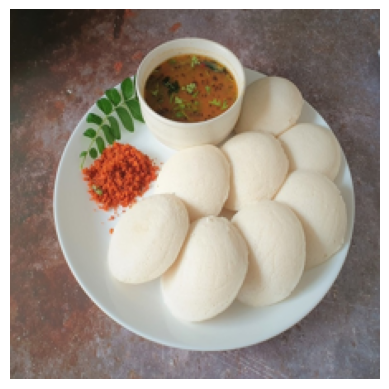

Food detected   : Idli (89%)
Visible condition: fresh-looking (98%)
This is not a food-safety determination.


In [25]:
from PIL import Image

def predict_image(model, class_names, path):
    img = Image.open(path).convert("RGB").resize(IMG_SIZE)
    arr = np.array(img, dtype="float32")
    return model.predict(arr[None], verbose=0)[0], img

uploaded = files.upload()
path = next(iter(uploaded))

food_probs, img = predict_image(food_model, food_classes, path)
spoil_probs, _  = predict_image(spoil_model, spoil_classes, path)

food_idx = int(np.argmax(food_probs))
cond, cond_conf = visual_condition(spoil_probs, spoil_classes)

plt.imshow(img); plt.axis("off"); plt.show()
print(f"Food detected   : {food_classes[food_idx]} ({food_probs[food_idx]:.0%})")
if food_probs[food_idx] < FOOD_THRESHOLD:
    print("  ⚠️ Low confidence. Please confirm the food name manually.")
print(f"Visible condition: {cond} ({cond_conf:.0%})")
print("This is not a food-safety determination.")

**Section 15: Create the Web Application Using Streamlit**
The code creates `app.py` with five pages:

1. **Home**: introduction and live counts
2. **Food Analysis**: upload a photo, see food name, confidence and visible condition
3. **Donation Registration**: enter quantity, preparation time, storage details and pickup info
4. **Time & Storage Assessment**: eligibility status, collection deadline and warnings
5. **NGO Dashboard**: view eligible donations, request them and update pickup status

Donations are stored in an SQLite database. Times are handled in India Standard Time.

In [26]:
%%writefile /content/app.py
import streamlit as st
import sqlite3, json, os, sys
import numpy as np
from datetime import datetime, timedelta, time as dtime
from zoneinfo import ZoneInfo
from PIL import Image
import tensorflow as tf

BASE_DIR = "/content/rescuebite"
sys.path.insert(0, BASE_DIR)
from assessment import assess_donation, STATUS_TEXT

MODEL_DIR = f"{BASE_DIR}/models"
DB_PATH = f"{BASE_DIR}/rescuebite.db"
IST = ZoneInfo("Asia/Kolkata")

st.set_page_config(page_title="RescueBite", page_icon="🍱", layout="wide")

STORAGE_OPTIONS = {
    "Room temperature": "room_temperature",
    "Hot-held (kept hot)": "hot_held",
    "Refrigerated": "refrigerated",
    "Not sure": "unknown",
}
STATUS_ICON = {"ELIGIBLE_FOR_REVIEW": "🟢", "NEEDS_VERIFICATION": "🟡", "NOT_ELIGIBLE": "🔴"}


def now_ist():
    return datetime.now(IST).replace(tzinfo=None)


# ------------------------------------------------------------ database
def get_conn():
    conn = sqlite3.connect(DB_PATH)
    conn.row_factory = sqlite3.Row
    return conn


def init_db():
    with get_conn() as c:
        c.execute("""CREATE TABLE IF NOT EXISTS donations (
            id INTEGER PRIMARY KEY AUTOINCREMENT,
            created_at TEXT, food_name TEXT, quantity TEXT,
            prep_time TEXT, storage TEXT, storage_temp REAL, ambient_temp REAL,
            hours_before_storage REAL, pickup_location TEXT, contact TEXT,
            pickup_time TEXT, visual_condition TEXT,
            food_confidence REAL, spoil_confidence REAL,
            status TEXT, ngo_status TEXT DEFAULT 'Available')""")


init_db()


def run_assessment(row, now=None):
    return assess_donation(
        prep_time=datetime.fromisoformat(row["prep_time"]),
        now=now or now_ist(),
        pickup_time=datetime.fromisoformat(row["pickup_time"]) if row["pickup_time"] else None,
        storage=row["storage"],
        storage_temp_c=row["storage_temp"],
        ambient_temp_c=row["ambient_temp"],
        hours_at_room_temp_before_storage=row["hours_before_storage"],
        visual_condition=row["visual_condition"],
    )


# ------------------------------------------------------------ models
@st.cache_resource
def load_models():
    food = tf.keras.models.load_model(f"{MODEL_DIR}/food_model.keras")
    spoil = tf.keras.models.load_model(f"{MODEL_DIR}/spoilage_model.keras")
    with open(f"{MODEL_DIR}/meta.json") as f:
        meta = json.load(f)
    return food, spoil, meta


def predict(model, img, size):
    arr = np.array(img.convert("RGB").resize(tuple(size)), dtype="float32")
    return model.predict(arr[None], verbose=0)[0]


def show_assessment(result):
    icon = STATUS_ICON[result["status"]]
    msg = f"{icon} {STATUS_TEXT[result['status']]}"
    if result["status"] == "ELIGIBLE_FOR_REVIEW":
        st.success(msg)
    elif result["status"] == "NEEDS_VERIFICATION":
        st.warning(msg)
    else:
        st.error(msg)
    c1, c2 = st.columns(2)
    if result["safe_until"]:
        c1.metric("Safe window ends (per entered details)", result["safe_until"].strftime("%d %b, %I:%M %p"))
    if result["collect_by"]:
        c2.metric("Collect by", result["collect_by"].strftime("%d %b, %I:%M %p"))
    for t in result["reasons"]:
        st.write("• " + t)
    for t in result["warnings"]:
        st.write("⚠️ " + t)


# ------------------------------------------------------------ pages
def page_home():
    st.title("🍱 RescueBite")
    st.subheader("Deep learning-based food recognition, spoilage detection and surplus food rescue")
    st.write(
        "Upload a food photo, enter when and how it was stored, and RescueBite checks "
        "whether the donation can go to NGO review and by when it should be collected."
    )
    st.info(
        "The photo analysis only recognises the food and visible spoilage. The collection deadline "
        "comes from the preparation time and storage details you enter. A person must always make the "
        "final food-safety check."
    )
    with get_conn() as c:
        total = c.execute("SELECT COUNT(*) FROM donations").fetchone()[0]
        collected = c.execute("SELECT COUNT(*) FROM donations WHERE ngo_status='Collected'").fetchone()[0]
    a, b = st.columns(2)
    a.metric("Donations registered", total)
    b.metric("Donations collected", collected)


def page_analysis():
    st.title("🔍 Food Analysis")
    try:
        food_model, spoil_model, meta = load_models()
    except Exception as e:
        st.error(f"Models not found. Run the training sections first. ({e})")
        return

    up = st.file_uploader("Upload a food image", type=["jpg", "jpeg", "png"])
    if up is None:
        return
    img = Image.open(up)
    st.image(img, width=350)

    if st.button("Analyse food"):
        size = meta["img_size"]
        fp = predict(food_model, img, size)
        sp = predict(spoil_model, img, size)

        top3 = np.argsort(fp)[::-1][:3]
        food_name = meta["food_classes"][int(top3[0])]
        food_conf = float(fp[top3[0]])

        s_idx = int(np.argmax(sp)); s_conf = float(sp[s_idx])
        s_name = meta["spoilage_classes"][s_idx]
        if s_conf < meta["uncertain_threshold"]:
            cond = "uncertain"
        elif any(k in s_name.lower() for k in meta["spoiled_keywords"]):
            cond = "visible spoilage"
        else:
            cond = "fresh-looking"

        st.session_state["analysis"] = {
            "food_name": food_name, "food_conf": food_conf,
            "condition": cond, "spoil_conf": s_conf,
            "top3": [(meta["food_classes"][int(i)], float(fp[i])) for i in top3],
        }

    a = st.session_state.get("analysis")
    if a:
        c1, c2 = st.columns(2)
        c1.metric("Food detected", a["food_name"], f"{a['food_conf']:.0%} confidence")
        c2.metric("Visible condition", a["condition"].capitalize(), f"{a['spoil_conf']:.0%} confidence")
        if a["food_conf"] < meta["food_threshold"]:
            st.warning("Low confidence in the food name. Please confirm or correct it on the next page.")
        if a["condition"] == "uncertain":
            st.warning("Uncertain. This food needs further inspection by a person.")
        elif a["condition"] == "visible spoilage":
            st.error("Visible signs of spoilage were detected.")
        else:
            st.success("Looks fresh in the photo. This does not prove the food is safe to eat.")
        st.write("Top predictions:", ", ".join(f"{n} ({p:.0%})" for n, p in a["top3"]))
        st.caption("Go to **Donation Registration** to enter preparation and storage details.")


def page_donation():
    st.title("📝 Donation Registration")
    a = st.session_state.get("analysis")
    if not a:
        st.info("Please analyse a food image first on the **Food Analysis** page.")
        return

    st.write(f"Image result: **{a['food_name']}**, visible condition: **{a['condition']}**")
    now = now_ist()

    with st.form("donation_form"):
        food_name = st.text_input("Food name (edit if the prediction is wrong)", value=a["food_name"])
        quantity = st.text_input("Quantity (e.g. 25 plates, 10 kg)")
        c1, c2 = st.columns(2)
        prep_date = c1.date_input("Preparation date", value=now.date())
        prep_clock = c2.time_input("Preparation time", value=(now - timedelta(hours=1)).time())

        storage_label = st.selectbox("Storage method", list(STORAGE_OPTIONS.keys()))
        know_temp = st.checkbox("I know the storage temperature (°C)")
        storage_temp = st.number_input("Storage temperature (°C)", value=25.0, step=1.0)
        ambient = st.number_input("Room / outside temperature (°C)", value=30.0, step=1.0)
        before = st.number_input(
            "Hours the food stayed at room temperature BEFORE being hot-held or refrigerated",
            min_value=0.0, value=0.0, step=0.25)

        location = st.text_input("Pickup location")
        contact = st.text_input("Contact (name / phone)")
        d1, d2 = st.columns(2)
        pick_date = d1.date_input("Planned pickup date", value=now.date())
        pick_clock = d2.time_input("Planned pickup time", value=(now + timedelta(minutes=30)).time())
        submitted = st.form_submit_button("Submit donation")

    if submitted:
        if not quantity or not location or not contact:
            st.error("Please fill in quantity, pickup location and contact.")
            return
        row = {
            "prep_time": datetime.combine(prep_date, prep_clock).isoformat(),
            "pickup_time": datetime.combine(pick_date, pick_clock).isoformat(),
            "storage": STORAGE_OPTIONS[storage_label],
            "storage_temp": storage_temp if know_temp else None,
            "ambient_temp": ambient,
            "hours_before_storage": before,
            "visual_condition": a["condition"],
        }
        result = run_assessment(row, now)
        with get_conn() as c:
            cur = c.execute(
                """INSERT INTO donations (created_at, food_name, quantity, prep_time, storage,
                   storage_temp, ambient_temp, hours_before_storage, pickup_location, contact,
                   pickup_time, visual_condition, food_confidence, spoil_confidence, status)
                   VALUES (?,?,?,?,?,?,?,?,?,?,?,?,?,?,?)""",
                (now.isoformat(), food_name, quantity, row["prep_time"], row["storage"],
                 row["storage_temp"], row["ambient_temp"], row["hours_before_storage"],
                 location, contact, row["pickup_time"], row["visual_condition"],
                 a["food_conf"], a["spoil_conf"], result["status"]))
            st.session_state["last_id"] = cur.lastrowid
        st.success(f"Donation #{st.session_state['last_id']} registered.")
        show_assessment(result)


def page_assessment():
    st.title("⏱️ Time & Storage Assessment")
    with get_conn() as c:
        rows = c.execute("SELECT * FROM donations ORDER BY id DESC").fetchall()
    if not rows:
        st.info("No donations registered yet.")
        return
    ids = [r["id"] for r in rows]
    default = ids.index(st.session_state["last_id"]) if st.session_state.get("last_id") in ids else 0
    chosen = st.selectbox("Donation", ids, index=default,
                          format_func=lambda i: next(f"#{r['id']}: {r['food_name']}" for r in rows if r["id"] == i))
    row = next(r for r in rows if r["id"] == chosen)
    st.write(f"**{row['food_name']}**, {row['quantity']}  |  prepared {row['prep_time'].replace('T', ' ')[:16]}"
             f"  |  storage: {row['storage'].replace('_', ' ')}")
    st.caption("Assessed again using the current time.")
    show_assessment(run_assessment(row))


def page_ngo():
    st.title("🤝 NGO Dashboard")
    with get_conn() as c:
        rows = c.execute("SELECT * FROM donations ORDER BY id DESC").fetchall()
    if not rows:
        st.info("No donations yet.")
        return

    now = now_ist()
    st.subheader("Available donations (eligible for review)")
    shown = 0
    for r in rows:
        res = run_assessment(r, now)
        if r["ngo_status"] != "Available" or res["status"] != "ELIGIBLE_FOR_REVIEW":
            continue
        shown += 1
        left = res["collect_by"] - now
        with st.expander(f"#{r['id']}  {r['food_name']}  |  {r['quantity']}  |  collect by {res['collect_by'].strftime('%I:%M %p')}"):
            st.write(f"📍 {r['pickup_location']}   📞 {r['contact']}")
            st.write(f"⏳ About {int(left.total_seconds() // 60)} minutes left to collect")
            st.write(f"Image result: {r['visual_condition']}")
            st.caption("Eligibility is not a safety approval. Inspect the food on collection.")
            if st.button("Request this donation", key=f"req_{r['id']}"):
                with get_conn() as c:
                    c.execute("UPDATE donations SET ngo_status='Requested' WHERE id=?", (r["id"],))
                st.rerun()
    if shown == 0:
        st.write("No eligible donations right now.")

    st.subheader("Requested donations")
    for r in rows:
        if r["ngo_status"] == "Requested":
            st.write(f"#{r['id']} {r['food_name']} ({r['quantity']}), {r['pickup_location']}")
            if st.button("Mark as collected", key=f"col_{r['id']}"):
                with get_conn() as c:
                    c.execute("UPDATE donations SET ngo_status='Collected' WHERE id=?", (r["id"],))
                st.rerun()

    st.subheader("Awaiting verification (not shown to NGOs as eligible)")
    for r in rows:
        res = run_assessment(r, now)
        if r["ngo_status"] == "Available" and res["status"] == "NEEDS_VERIFICATION":
            st.write(f"🟡 #{r['id']} {r['food_name']}: " + " ".join(res["warnings"] + res["reasons"]))


# ------------------------------------------------------------ navigation
PAGES = {
    "🏠 Home": page_home,
    "🔍 Food Analysis": page_analysis,
    "📝 Donation Registration": page_donation,
    "⏱️ Time & Storage Assessment": page_assessment,
    "🤝 NGO Dashboard": page_ngo,
}
choice = st.sidebar.radio("Go to", list(PAGES.keys()))
PAGES[choice]()

Writing /content/app.py


**Section 16: Launch the Web App**
Streamlit runs inside Colab, and ngrok gives it a public link. Create a free account at ngrok.com, copy your authtoken and paste it when asked.

In [28]:
from getpass import getpass
from pyngrok import ngrok
import subprocess, time

ngrok.kill()
token = getpass("Enter your ngrok authtoken: ")
ngrok.set_auth_token(token)

process = subprocess.Popen([
    "streamlit", "run", "/content/app.py",
    "--server.port", "8501",
    "--server.address", "0.0.0.0",
    "--server.headless", "true"
])

time.sleep(8)

public_url = ngrok.connect(8501).public_url
print("Open your UI here:", public_url)

Enter your ngrok authtoken: ··········
Open your UI here: https://grub-sphinx-gigabyte.ngrok-free.dev


**Section 17: Limitations (for your report and viewa)**

* Image-based spoilage detection only reflects what is **visible** and what the training labels represent. It cannot detect bacteria, toxins or unsafe storage, so it must never be the only safety check.
* Model accuracy depends on the quality, size and variety of your datasets. Report accuracy only on the unseen test set.
* The time and storage limits in `CONFIG` are general guidance and placeholders. They must be set according to the food-safety rules that apply at the deployment location.
* Entered preparation and storage details are provided by the donor. A real deployment needs a way to verify them, plus human inspection at pickup.
* Colab sessions are temporary. Download the saved models (Section 11) and the database if you want to keep them.

**Working Flow of the Project**

Upload Food Image → Recognize Food → Check Visible Spoilage → Enter Preparation and Storage Details → Assess Time and Storage → Review Eligibility → NGO Requests and Collects